# Querying GeoConnex

`GeoConnex` queries the reference features at `reference.geoconnex.us`. It takes no key
and never receives `USGS_API_KEY`. This notebook lists the 22 two-digit hydrologic
regions of `hu02` without their geometry, streams them a few at a time, and maps the 18
regions of the contiguous United States with a CQL2 filter. `to_arrow()` turns each
result into a table for polars or geopandas, which needs the `arrow` extra.

In [1]:
from water_ogcapi import GeoConnex

gc = GeoConnex()

## List the regions

Geometry is most of a response. `skipGeometry` asks the server to leave it out, and
`keep_pages=True` keeps each page's bytes in `Page.content`, so the notebook can report
their size. `to_arrow()` on features without geometry returns a table of the properties
and the feature `id`, which polars reads.

In [2]:
regions = gc.collect("hu02", params={"skipGeometry": "true"}, keep_pages=True)
print(len(regions.geojson["features"]), "regions in", regions.pagination.page_count, "page(s)")
print(regions.pagination.completeness, regions.pagination.checks)
print(sum(len(page.content) for page in regions.pages) / 1e3, "kB")

22 regions in 1 page(s)
complete ('end_of_links', 'count', 'unique_ids')
13.623 kB


In [3]:
import polars as pl

pl.Config.set_tbl_rows(22)
pl.from_arrow(regions.to_arrow()).select("id", "name", "gnis_id").sort("id")

id,name,gnis_id
str,str,i64
"""01""","""New England Region""",2730131
"""02""","""Mid Atlantic Region""",2730132
"""03""","""South Atlantic-Gulf Region""",2730133
"""04""","""Great Lakes Region""",2730134
"""05""","""Ohio Region""",2730135
"""06""","""Tennessee Region""",2730136
"""07""","""Upper Mississippi Region""",2730137
"""08""","""Lower Mississippi Region""",2730138
"""09""","""Souris-Red-Rainy Region""",2730139


## Stream pages

`iter_pages()` yields one `Page` per response and follows each page's `next` link. A
`limit` of 10 splits the 22 regions into three pages. GeoConnex reports `numberMatched`
on every page.

In [4]:
for page in gc.iter_pages("hu02", params={"skipGeometry": "true", "limit": "10"}):
    print(page.status, page.feature_count, page.number_matched)

200 10 22


200 10 22


200 2 22


## Filter with CQL2

`queryables()` lists the properties of a collection that a filter can name:

In [5]:
print(", ".join(gc.queryables("hu02").properties))

geometry, fid, uri, name, gnis_url, gnis_id, huc2, loaddate


`huc2` is a string, so a CQL2-Text `filter` of `huc2 <= '18'` keeps the 18 regions of the
contiguous United States and leaves out Alaska, Hawaii, the Caribbean, and the South
Pacific, which sit far from the rest. With geometry, the response is much larger than
the list above.

In [6]:
conus = gc.collect("hu02", filter="huc2 <= '18'", keep_pages=True)
print(len(conus.geojson["features"]), "regions,", end=" ")
print(round(sum(len(page.content) for page in conus.pages) / 1e6), "MB")
print(conus.pagination.completeness, conus.pagination.checks)
print(conus.crs.effective, conus.crs.source)

18 regions, 23 MB
complete ('end_of_links', 'count', 'unique_ids')
http://www.opengis.net/def/crs/OGC/1.3/CRS84 content_crs


## Map the regions

`to_arrow()` returns a pyarrow Table whose `geometry` column carries the CRS, so
geopandas reads it as a GeoDataFrame with that CRS. EPSG:5070 is an equal-area
projection of the contiguous United States, so the polygon areas it gives are true areas.

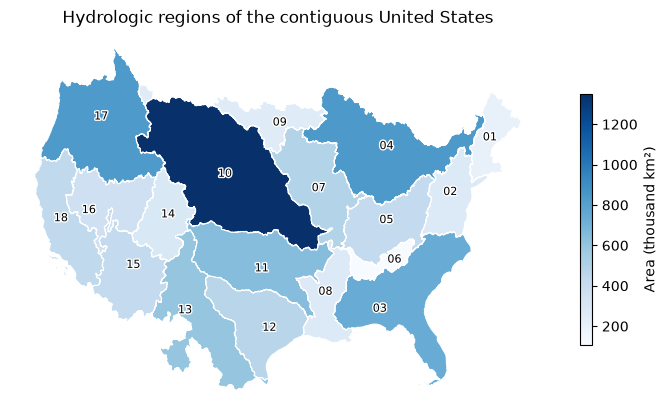

In [7]:
import geopandas as gpd
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt

frame = gpd.GeoDataFrame.from_arrow(conus.to_arrow()).to_crs(5070)
frame["area"] = frame.area / 1e9  # thousand km²
ax = frame.plot(
    column="area",
    cmap="Blues",
    edgecolor="white",
    linewidth=0.8,
    figsize=(7, 4.6),
    legend=True,
    legend_kwds={"label": "Area (thousand km²)", "shrink": 0.6},
)
for point, code in zip(frame.representative_point(), frame["huc2"], strict=True):
    ax.annotate(
        code,
        (point.x, point.y),
        ha="center",
        va="center",
        fontsize=8,
        path_effects=[pe.withStroke(linewidth=2, foreground="white")],
    )
ax.set(title="Hydrologic regions of the contiguous United States")
ax.set_axis_off()
plt.tight_layout()

In [8]:
gc.close()